Revised notebook
Start with 'model_evaluation.ipynb' for corrected nested evaluation.
This legacy notebook retains the wider model exploration/export workflow.

In [1]:
%pip install -U numpy pandas matplotlib seaborn scipy scikit-learn xgboost lightgbm shap imbalanced-learn joblib

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 932.9 kB/s eta 0:00:01
   -------------------------------------- 751.9/751.9 kB 979.5 kB/s eta 0:00:00
  Attempting uninstall: shap
    Found existing installation: shap 0.53.0
    Uninstalling shap-0.53.0:
      Successfully uninstalled shap-0.53.0
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip uninstall -y scikit-learn shap
%pip install --no-cache-dir scikit-learn shap

Found existing installation: scikit-learn 1.9.1
Uninstalling scikit-learn-1.9.1:
  Successfully uninstalled scikit-learn-1.9.1
Found existing installation: shap 0.54.1
Uninstalling shap-0.54.1:
  Successfully uninstalled shap-0.54.1
Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 932.9 kB/s eta 0:00:09
   --- ------------------------------------ 0.8/8.3 MB 987.4 kB/s eta 0:00:08
   ----- ---------------------------------- 1.0/8.3 MB 1.0 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.3 MB 1.1 MB/s eta 0:00:07
   ------- -------------------------------- 1.6/8.3 MB 1.1 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.3 MB 1.2 MB/s eta 0:00:06
   -------- ----------------------


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    RepeatedStratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from scipy.stats import wilcoxon

import shap

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from pathlib import Path
PCOS_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'PCOS_dataset.csv').is_file() and (p / 'pcos-insight-frontend').is_dir()), None)
if PCOS_ROOT is None:
    raise RuntimeError('Open this notebook from the PCOS project folder.')
df = pd.read_csv(PCOS_ROOT / 'PCOS_dataset.csv')
print('Shape:', df.shape)


In [5]:
df.head(20)

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN
5,6,6,0,36,74.1,165.0,27.217631,15,78,28,...,0.0,0,110,70,9,6,16.0,20.0,8.0,NaN
6,7,7,0,34,64.0,156.0,26.298488,11,72,18,...,0.0,0,120,80,6,6,15.0,16.0,6.8,NaN
7,8,8,0,33,58.5,159.0,23.139907,13,72,20,...,0.0,0,120,80,7,6,15.0,18.0,7.1,NaN
8,9,9,0,32,40.0,158.0,16.023073,11,72,18,...,0.0,0,120,80,5,7,17.0,17.0,4.2,NaN
9,10,10,0,36,52.0,150.0,23.111111,15,80,20,...,0.0,0,110,80,1,1,14.0,17.0,2.5,NaN


In [6]:
print(df.columns.tolist())

['Sl. No', 'Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)', 'Unnamed: 44']


In [7]:
df.isnull().sum()

Sl. No                      0
Patient File No.            0
PCOS (Y/N)                  0
 Age (yrs)                  0
Weight (Kg)                 0
Height(Cm)                  0
BMI                         0
Blood Group                 0
Pulse rate(bpm)             0
RR (breaths/min)            0
Hb(g/dl)                    0
Cycle(R/I)                  0
Cycle length(days)          0
Marraige Status (Yrs)       1
Pregnant(Y/N)               0
No. of aborptions           0
  I   beta-HCG(mIU/mL)      0
II    beta-HCG(mIU/mL)      0
FSH(mIU/mL)                 0
LH(mIU/mL)                  0
FSH/LH                      0
Hip(inch)                   0
Waist(inch)                 0
Waist:Hip Ratio             0
TSH (mIU/L)                 0
AMH(ng/mL)                  0
PRL(ng/mL)                  0
Vit D3 (ng/mL)              0
PRG(ng/mL)                  0
RBS(mg/dl)                  0
Weight gain(Y/N)            0
hair growth(Y/N)            0
Skin darkening (Y/N)        0
Hair loss(

## 2. Data preparation and quality assessment

In [8]:
df.drop(columns=['Sl. No', 'Patient File No.', 'Unnamed: 44'], inplace=True)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape

(541, 42)

In [11]:
df.isnull().sum()

PCOS (Y/N)                0
 Age (yrs)                0
Weight (Kg)               0
Height(Cm)                0
BMI                       0
Blood Group               0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Cycle(R/I)                0
Cycle length(days)        0
Marraige Status (Yrs)     1
Pregnant(Y/N)             0
No. of aborptions         0
  I   beta-HCG(mIU/mL)    0
II    beta-HCG(mIU/mL)    0
FSH(mIU/mL)               0
LH(mIU/mL)                0
FSH/LH                    0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
TSH (mIU/L)               0
AMH(ng/mL)                0
PRL(ng/mL)                0
Vit D3 (ng/mL)            0
PRG(ng/mL)                0
RBS(mg/dl)                0
Weight gain(Y/N)          0
hair growth(Y/N)          0
Skin darkening (Y/N)      0
Hair loss(Y/N)            0
Pimples(Y/N)              0
Fast food (Y/N)           1
Reg.Exercise(Y/N)         0
BP _Systolic (mmHg) 

In [12]:
df[df['Marraige Status (Yrs)'].isnull()]

,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
458,1,36,66.0,162.0,25.1,15,72,20,11.0,4,...,0,0.0,0,120,80,14,5,19.0,19.0,8.0


In [13]:
df[df['Fast food (Y/N)'].isnull()]

,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
156,0,27,53.2,158.0,21.3,13,72,22,10.5,4,...,0,NaN,1,120,70,5,7,11.0,13.0,11.0


In [14]:
# Missing fast-food values must be learned inside each training pipeline.
# No full-dataset mode imputation is performed here.
print('Fast-food missing values retained for fold-local imputation:',
      df['Fast food (Y/N)'].isna().sum())

Fast-food missing values retained for fold-local imputation: 1


In [15]:
df.drop(columns=['Marraige Status (Yrs)', 'Pulse rate(bpm) ', 'RR (breaths/min)'], inplace=True)

In [16]:
df = df.drop(columns=['Pregnant(Y/N)'])

In [17]:
df.drop(columns=['Blood Group', 'Hb(g/dl)', 'No. of aborptions'], inplace=True)

In [18]:
df.drop(columns=['BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'RBS(mg/dl)', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)'], inplace=True)

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PCOS (Y/N)            541 non-null    int64  
 1    Age (yrs)            541 non-null    int64  
 2   Weight (Kg)           541 non-null    float64
 3   Height(Cm)            541 non-null    float64
 4   BMI                   541 non-null    float64
 5   Cycle(R/I)            541 non-null    int64  
 6   Cycle length(days)    541 non-null    int64  
 7   FSH(mIU/mL)           541 non-null    float64
 8   LH(mIU/mL)            541 non-null    float64
 9   FSH/LH                541 non-null    float64
 10  Hip(inch)             541 non-null    int64  
 11  Waist(inch)           541 non-null    int64  
 12  Waist:Hip Ratio       541 non-null    float64
 13  TSH (mIU/L)           541 non-null    float64
 14  AMH(ng/mL)            541 non-null    str    
 15  PRL(ng/mL)            541 non-null

In [20]:
df.head()

,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Cycle(R/I),Cycle length(days),FSH(mIU/mL),LH(mIU/mL),FSH/LH,...,Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,0,28,44.6,152.0,19.300000,2,5,7.95,3.68,2.160326,...,0,0,0,1.0,0,3,3,18.0,18.0,8.5
1,0,36,65.0,161.5,24.921163,2,5,6.73,1.09,6.174312,...,0,0,0,0.0,0,3,5,15.0,14.0,3.7
2,1,33,68.8,165.0,25.270891,2,5,5.54,0.88,6.295455,...,0,1,1,1.0,0,13,15,18.0,20.0,10.0
3,0,37,65.0,148.0,29.674945,2,5,8.06,2.36,3.415254,...,0,0,0,0.0,0,2,2,15.0,14.0,7.5
4,0,25,52.0,161.0,20.060954,2,5,3.98,0.90,4.422222,...,0,1,0,0.0,0,3,4,16.0,14.0,7.0


In [21]:
print(df['AMH(ng/mL)'].unique()[:20])

<ArrowStringArray>
['2.07', '1.53', '6.63', '1.22', '2.26', '6.74', '3.05', '1.54',    '1',
 '1.61', '4.47', '1.67', '7.94', '2.38', '0.88', '0.69', '3.78', '1.92',
 '2.85', '2.13']
Length: 20, dtype: str


In [22]:
df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

In [23]:
df[['AMH(ng/mL)']].dtypes

AMH(ng/mL)    float64
dtype: object

In [24]:
df_model = df.copy()

In [25]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PCOS (Y/N)            541 non-null    int64  
 1    Age (yrs)            541 non-null    int64  
 2   Weight (Kg)           541 non-null    float64
 3   Height(Cm)            541 non-null    float64
 4   BMI                   541 non-null    float64
 5   Cycle(R/I)            541 non-null    int64  
 6   Cycle length(days)    541 non-null    int64  
 7   FSH(mIU/mL)           541 non-null    float64
 8   LH(mIU/mL)            541 non-null    float64
 9   FSH/LH                541 non-null    float64
 10  Hip(inch)             541 non-null    int64  
 11  Waist(inch)           541 non-null    int64  
 12  Waist:Hip Ratio       541 non-null    float64
 13  TSH (mIU/L)           541 non-null    float64
 14  AMH(ng/mL)            540 non-null    float64
 15  PRL(ng/mL)            541 non-null

In [26]:
df_model.shape

(541, 30)

In [27]:
print(df_model.columns.tolist())

['PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Cycle(R/I)', 'Cycle length(days)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


In [28]:
print(df_model.shape)
print(df_model.columns.tolist())

(541, 30)
['PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Cycle(R/I)', 'Cycle length(days)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


In [29]:
redundant_features = [
    'Weight (Kg)',
    'Height(Cm) ',
    'Hip(inch)',
    'Waist(inch)',
    'FSH/LH'
]

df_model = df_model.drop(columns=redundant_features)

In [30]:
print(df_model.shape)
print(df_model.columns.tolist())

(541, 25)
['PCOS (Y/N)', ' Age (yrs)', 'BMI', 'Cycle(R/I)', 'Cycle length(days)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


In [31]:
print("Duplicate rows:", df_model.duplicated().sum())

Duplicate rows: 0


## 3. Exploratory analysis and target distribution

PCOS (Y/N)
0    67.28
1    32.72
Name: proportion, dtype: float64
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64


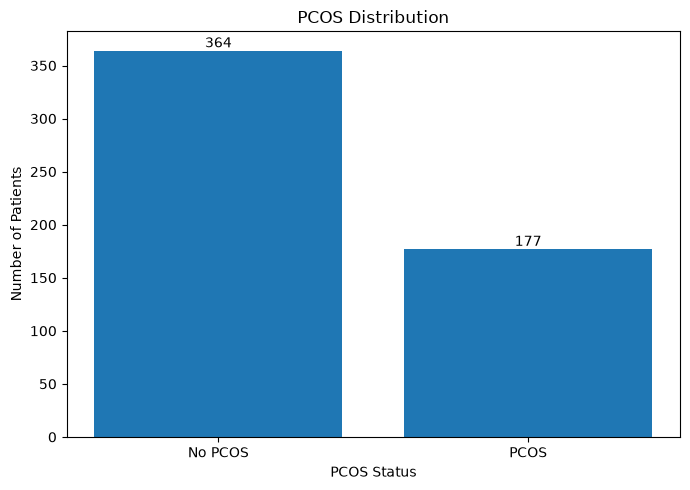

In [32]:
print(
    df_model['PCOS (Y/N)']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
pcos_counts = df_model['PCOS (Y/N)'].value_counts()
print(pcos_counts)

labels = ['No PCOS', 'PCOS']
counts = [
    pcos_counts.get(0, 0),
    pcos_counts.get(1, 0)
]

plt.figure(figsize=(7, 5))

bars = plt.bar(labels, counts)

plt.xlabel('PCOS Status')
plt.ylabel('Number of Patients')
plt.title('PCOS Distribution')

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

In [33]:
df_model.describe().T

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),541.0,0.327172,0.469615,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),541.0,31.430684,5.411006,20.000000,28.000000,31.000000,35.000000,48.000000
BMI,541.0,24.311285,4.056399,12.417882,21.641274,24.238227,26.634958,38.900000
Cycle(R/I),541.0,2.560074,0.901950,2.000000,2.000000,2.000000,4.000000,5.000000
Cycle length(days),541.0,4.940850,1.492020,0.000000,4.000000,5.000000,5.000000,12.000000
FSH(mIU/mL),541.0,14.601832,217.022081,0.210000,3.300000,4.850000,6.410000,5052.000000
LH(mIU/mL),541.0,6.469919,86.673255,0.020000,1.020000,2.300000,3.680000,2018.000000
Waist:Hip Ratio,541.0,0.891895,0.046326,0.755556,0.857143,0.894737,0.928571,0.979167
TSH (mIU/L),541.0,2.981281,3.755532,0.040000,1.480000,2.260000,3.570000,65.000000
AMH(ng/mL),540.0,5.624191,5.881608,0.100000,2.010000,3.700000,6.925000,66.000000


In [34]:
cols_to_check = [
    'FSH(mIU/mL)',
    'LH(mIU/mL)',
    'TSH (mIU/L)',
    'AMH(ng/mL)',
    'Vit D3 (ng/mL)',
    'PRG(ng/mL)'
]

for col in cols_to_check:
    print(f"\n===== {col} =====")
    print(
        df_model.loc[
            df_model[col] > df_model[col].quantile(0.99),
            ['PCOS (Y/N)', col]
        ].sort_values(col, ascending=False).head(10)
    )


===== FSH(mIU/mL) =====
     PCOS (Y/N)  FSH(mIU/mL)
329           0      5052.00
250           1        65.40
281           0        60.37
412           1        40.08
195           1        22.00
78            0        15.45

===== LH(mIU/mL) =====
     PCOS (Y/N)  LH(mIU/mL)
455           1     2018.00
120           0       14.69
328           1       14.24
153           1       12.95
449           1       12.04
131           0       10.75

===== TSH (mIU/L) =====
     PCOS (Y/N)  TSH (mIU/L)
37            0        65.00
233           0        25.91
278           1        22.59
346           1        20.85
535           0        17.20
168           1        16.99

===== AMH(ng/mL) =====
     PCOS (Y/N)  AMH(ng/mL)
267           1        66.0
180           1        32.0
402           1        28.6
268           0        26.8
213           1        26.4
445           1        26.4

===== Vit D3 (ng/mL) =====
     PCOS (Y/N)  Vit D3 (ng/mL)
191           1         6014.66
195         

In [35]:
skewed_features = [
    'FSH(mIU/mL)',
    'LH(mIU/mL)',
    'TSH (mIU/L)',
    'AMH(ng/mL)',
    'PRL(ng/mL)',
    'Vit D3 (ng/mL)',
    'PRG(ng/mL)'
]

print("SKEWNESS")
print(df_model[skewed_features].skew().sort_values(ascending=False))

print("\nZERO COUNTS")
zero_counts = (df_model == 0).sum()
print(zero_counts[zero_counts > 0])

print("\nMISSING VALUES")
print(df_model.isnull().sum()[df_model.isnull().sum() > 0])

print("\nCYCLE ENCODING")
print(df_model['Cycle(R/I)'].value_counts().sort_index())

SKEWNESS
FSH(mIU/mL)       23.244530
LH(mIU/mL)        23.234664
PRG(ng/mL)        20.730654
Vit D3 (ng/mL)    16.436558
TSH (mIU/L)        9.790706
AMH(ng/mL)         3.293206
PRL(ng/mL)         2.441412
dtype: float64

ZERO COUNTS
PCOS (Y/N)              364
Cycle length(days)        1
Vit D3 (ng/mL)            1
Weight gain(Y/N)        337
hair growth(Y/N)        393
Skin darkening (Y/N)    375
Hair loss(Y/N)          296
Pimples(Y/N)            276
Fast food (Y/N)         262
Reg.Exercise(Y/N)       407
Follicle No. (L)         10
Follicle No. (R)         11
Avg. F size (L) (mm)      7
Avg. F size (R) (mm)      1
Endometrium (mm)          2
dtype: int64

MISSING VALUES
AMH(ng/mL)         1
Fast food (Y/N)    1
dtype: int64

CYCLE ENCODING
Cycle(R/I)
2    390
4    150
5      1
Name: count, dtype: int64


| Feature    | Your maximum | Reference context                                                                                                                                                     | My decision                                          |
| ---------- | -----------: | --------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------- |
| **FSH**    |     **5052** | Premenopausal FSH is roughly 1.4–23.2 IU/L depending on cycle phase; even postmenopausal reference is 16–157 IU/L. ([Mayo Clinic Laboratories][1])                    | **5052 → clearly implausible → flag as erroneous**   |
| **LH**     |     **2018** | Premenopausal values vary by cycle phase; Mayo gives follicular 1.9–14.6 and midcycle up to 118 IU/L; postmenopausal up to 65.4 IU/L. ([Mayo Clinic Laboratories][2]) | **2018 → clearly implausible → flag**                |
| **TSH**    |       **65** | Adult reference roughly 0.3–4.2 mIU/L; high TSH can occur with genuine hypothyroidism. ([Mayo Clinic Laboratories][3])                                                | **Do NOT automatically remove**                      |
| **AMH**    |       **66** | Age-specific female upper ranges are generally ~8–12 ng/mL for ages 20–34 and lower thereafter. ([Mayo Clinic Laboratories][4])                                       | **66 → highly suspicious → flag**                    |
| **PRL**    |   **128.24** | Adult female reference ~4.8–23.3 ng/mL, but genuine pathological elevations can be much higher. ([Mayo Clinic Laboratories][5])                                       | **Abnormal, but don't automatically call erroneous** |
| **Vit D3** |  **6014.66** | >80 ng/mL is already considered a possible toxicity range. ([Mayo Clinic Laboratories][6])                                                                            | **6014/5418 → clearly implausible → flag**           |
| **PRG**    |       **85** | Depends heavily on cycle phase: follicular ≤0.89, ovulation ≤12, luteal 1.8–24; pregnancy has much higher ranges. ([Mayo Clinic Laboratories][7])                     | **85 → investigate; don't blindly delete**           |

[1]: https://www.mayocliniclabs.com/test-catalog/overview/602753?utm_source=chatgpt.com "FSH - Overview: Follicle-Stimulating Hormone (FSH), Serum"
[2]: https://www.mayocliniclabs.com/test-catalog/Overview/602752?utm_source=chatgpt.com "LH - Overview: Luteinizing Hormone (LH), Serum"
[3]: https://www.mayocliniclabs.com/test-catalog/download-setup?format=pdf&unit_code=800096&utm_source=chatgpt.com "Test Definition: STSH"
[4]: https://www.mayocliniclabs.com/test-catalog/overview/608824?utm_source=chatgpt.com "AMH1 - Overview: Antimullerian Hormone, Serum"
[5]: https://www.mayocliniclabs.com/test-catalog/Overview/85670?utm_source=chatgpt.com "PRL - Overview: Prolactin, Serum"
[6]: https://www.mayocliniclabs.com/test-catalog/Overview/800262?utm_source=chatgpt.com "25HDN - Overview: 25-Hydroxyvitamin D2 and D3, Serum"
[7]: https://www.mayocliniclabs.com/test-catalog/overview/8141?utm_source=chatgpt.com "PGSN - Overview: Progesterone, Serum"


In [36]:
outlier_summary = []

features_to_check = [
    'FSH(mIU/mL)',
    'LH(mIU/mL)',
    'TSH (mIU/L)',
    'AMH(ng/mL)',
    'PRL(ng/mL)',
    'Vit D3 (ng/mL)',
    'PRG(ng/mL)'
]

for col in features_to_check:
    q1 = df_model[col].quantile(0.25)
    q3 = df_model[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_summary.append({
        'Feature': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower_IQR': lower,
        'Upper_IQR': upper,
        'IQR_Outliers': ((df_model[col] < lower) |
                         (df_model[col] > upper)).sum()
    })

outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df)

          Feature     Q1      Q3     IQR  Lower_IQR  Upper_IQR  IQR_Outliers
0     FSH(mIU/mL)   3.30   6.410   3.110    -1.3650    11.0750            12
1      LH(mIU/mL)   1.02   3.680   2.660    -2.9700     7.6700            24
2     TSH (mIU/L)   1.48   3.570   2.090    -1.6550     6.7050            27
3      AMH(ng/mL)   2.01   6.925   4.915    -5.3625    14.2975            52
4      PRL(ng/mL)  14.52  29.890  15.370    -8.5350    52.9450            21
5  Vit D3 (ng/mL)  20.80  34.500  13.700     0.2500    55.0500            31
6      PRG(ng/mL)   0.25   0.450   0.200    -0.0500     0.7500            39


In [37]:
clinical_flags = {
    'FSH(mIU/mL)': 100,
    'LH(mIU/mL)': 150,
    'AMH(ng/mL)': 20,
    'Vit D3 (ng/mL)': 150
}

In [38]:
df_model['FSH_outlier'] = df_model['FSH(mIU/mL)'] > 100
df_model['LH_outlier'] = df_model['LH(mIU/mL)'] > 150
df_model['AMH_outlier'] = df_model['AMH(ng/mL)'] > 20
df_model['VitD_outlier'] = df_model['Vit D3 (ng/mL)'] > 150

In [39]:
print(df_model[
    ['FSH_outlier',
     'LH_outlier',
     'AMH_outlier',
     'VitD_outlier']
].sum())

FSH_outlier      1
LH_outlier       1
AMH_outlier     12
VitD_outlier     2
dtype: int64


Extreme observations were first identified using statistical outlier detection and subsequently assessed against clinical reference information. Values considered clinically implausible were treated as missing rather than replaced with arbitrary values. Clinically abnormal but plausible observations were retained. Missing/outlier-derived values were subsequently imputed using a training-set-only strategy.

In [40]:
flagged_cols = [
    'PCOS (Y/N)',
    'FSH(mIU/mL)',
    'LH(mIU/mL)',
    'AMH(ng/mL)',
    'Vit D3 (ng/mL)'
]

print(
    df_model.loc[
        df_model[
            ['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']
        ].any(axis=1),
        flagged_cols
    ].sort_values(
        ['FSH(mIU/mL)', 'LH(mIU/mL)', 'AMH(ng/mL)', 'Vit D3 (ng/mL)'],
        ascending=False
    )
)

     PCOS (Y/N)  FSH(mIU/mL)  LH(mIU/mL)  AMH(ng/mL)  Vit D3 (ng/mL)
329           0      5052.00       3.680        3.50           28.60
195           1        22.00       3.390        6.65         5418.60
267           1         7.35       3.610       66.00           30.20
279           0         5.81       3.910       21.00           20.10
346           1         5.50       3.030       20.40           10.50
268           0         5.46       0.910       26.80           21.40
402           1         5.18       6.020       28.60           21.20
113           1         5.02       7.520       21.00           32.90
217           1         4.76       2.700       22.00           22.70
455           1         4.33    2018.000        7.70           41.04
293           1         4.25       5.110       21.80           23.30
110           0         4.13       5.110       21.90           33.40
213           1         3.63       8.340       26.40           22.40
445           1         3.63      

In [41]:
outlier_mask = df_model[['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']].any(axis=1)
print(df_model.loc[outlier_mask, [
    'PCOS (Y/N)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'AMH(ng/mL)', 'Vit D3 (ng/mL)'
]].sort_values(
    ['FSH(mIU/mL)', 'LH(mIU/mL)', 'AMH(ng/mL)', 'Vit D3 (ng/mL)'],
    ascending=False
))


     PCOS (Y/N)  FSH(mIU/mL)  LH(mIU/mL)  AMH(ng/mL)  Vit D3 (ng/mL)
329           0      5052.00       3.680        3.50           28.60
195           1        22.00       3.390        6.65         5418.60
267           1         7.35       3.610       66.00           30.20
279           0         5.81       3.910       21.00           20.10
346           1         5.50       3.030       20.40           10.50
268           0         5.46       0.910       26.80           21.40
402           1         5.18       6.020       28.60           21.20
113           1         5.02       7.520       21.00           32.90
217           1         4.76       2.700       22.00           22.70
455           1         4.33    2018.000        7.70           41.04
293           1         4.25       5.110       21.80           23.30
110           0         4.13       5.110       21.90           33.40
213           1         3.63       8.340       26.40           22.40
445           1         3.63      

In [42]:
# Treat only clinically implausible values flagged above as missing.
for col, flag_col in {
    'FSH(mIU/mL)': 'FSH_outlier',
    'LH(mIU/mL)': 'LH_outlier',
    'AMH(ng/mL)': 'AMH_outlier',
    'Vit D3 (ng/mL)': 'VitD_outlier'
}.items():
    df_model.loc[df_model[flag_col], col] = np.nan

print('Values converted to NaN:', int(outlier_mask.sum()))


Values converted to NaN: 16


In [43]:
print(df_model.isnull().sum()[df_model.isnull().sum() > 0])

FSH(mIU/mL)         1
LH(mIU/mL)          1
AMH(ng/mL)         13
Vit D3 (ng/mL)      2
Fast food (Y/N)     1
dtype: int64


In [44]:
zero_cols = [
    'Cycle length(days)',
    'Vit D3 (ng/mL)',
    'Follicle No. (L)',
    'Follicle No. (R)',
    'Avg. F size (L) (mm)',
    'Avg. F size (R) (mm)',
    'Endometrium (mm)'
]

for col in zero_cols:
    print(f"\n{col}")
    print(df_model[df_model[col] == 0][['PCOS (Y/N)', col]])


Cycle length(days)
    PCOS (Y/N)  Cycle length(days)
39           0                   0

Vit D3 (ng/mL)
     PCOS (Y/N)  Vit D3 (ng/mL)
216           1             0.0

Follicle No. (L)
     PCOS (Y/N)  Follicle No. (L)
18            0                 0
42            0                 0
75            0                 0
78            0                 0
128           0                 0
143           0                 0
146           0                 0
235           0                 0
251           0                 0
461           0                 0

Follicle No. (R)
     PCOS (Y/N)  Follicle No. (R)
103           0                 0
127           0                 0
261           0                 0
288           0                 0
298           0                 0
299           0                 0
409           0                 0
528           0                 0
531           0                 0
536           0                 0
538           0                 0

Avg. F size

In [45]:
df_model.loc[df_model['Cycle length(days)'] == 0, 'Cycle length(days)'] = np.nan

In [46]:
df_model.loc[df_model['Vit D3 (ng/mL)'] == 0, 'Vit D3 (ng/mL)'] = np.nan

In [47]:
df_model.loc[df_model['Avg. F size (L) (mm)'] == 0,
       'Avg. F size (L) (mm)'] = np.nan

df_model.loc[df_model['Avg. F size (R) (mm)'] == 0,
       'Avg. F size (R) (mm)'] = np.nan

In [48]:
df_model.loc[df_model['Endometrium (mm)'] == 0,
       'Endometrium (mm)'] = np.nan

In [49]:
print(df_model.isnull().sum()[df_model.isnull().sum() > 0])

Cycle length(days)       1
FSH(mIU/mL)              1
LH(mIU/mL)               1
AMH(ng/mL)              13
Vit D3 (ng/mL)           3
Fast food (Y/N)          1
Avg. F size (L) (mm)     7
Avg. F size (R) (mm)     1
Endometrium (mm)         2
dtype: int64


In [50]:
print(df_model['Cycle(R/I)'].value_counts().sort_index())

Cycle(R/I)
2    390
4    150
5      1
Name: count, dtype: int64


In [51]:
print(df_model.groupby('Cycle(R/I)')['PCOS (Y/N)'].agg(['count', 'sum', 'mean']))

            count  sum      mean
Cycle(R/I)                      
2             390   82  0.210256
4             150   94  0.626667
5               1    1  1.000000


In [52]:
df_model.loc[df_model['Cycle(R/I)'] == 5, 'Cycle(R/I)'] = np.nan

In [53]:
print(df_model.isnull().sum()[df_model.isnull().sum() > 0])

Cycle(R/I)               1
Cycle length(days)       1
FSH(mIU/mL)              1
LH(mIU/mL)               1
AMH(ng/mL)              13
Vit D3 (ng/mL)           3
Fast food (Y/N)          1
Avg. F size (L) (mm)     7
Avg. F size (R) (mm)     1
Endometrium (mm)         2
dtype: int64


In [54]:
print("Shape:", df_model.shape)

print("\nMissing values:")
print(df_model.isnull().sum()[df_model.isnull().sum() > 0])

print("\nData types:")
print(df_model.dtypes)

print("\nTarget distribution:")
print(df_model['PCOS (Y/N)'].value_counts())

Shape: (541, 29)

Missing values:
Cycle(R/I)               1
Cycle length(days)       1
FSH(mIU/mL)              1
LH(mIU/mL)               1
AMH(ng/mL)              13
Vit D3 (ng/mL)           3
Fast food (Y/N)          1
Avg. F size (L) (mm)     7
Avg. F size (R) (mm)     1
Endometrium (mm)         2
dtype: int64

Data types:
PCOS (Y/N)                int64
 Age (yrs)                int64
BMI                     float64
Cycle(R/I)              float64
Cycle length(days)      float64
FSH(mIU/mL)             float64
LH(mIU/mL)              float64
Waist:Hip Ratio         float64
TSH (mIU/L)             float64
AMH(ng/mL)              float64
PRL(ng/mL)              float64
Vit D3 (ng/mL)          float64
PRG(ng/mL)              float64
Weight gain(Y/N)          int64
hair growth(Y/N)          int64
Skin darkening (Y/N)      int64
Hair loss(Y/N)            int64
Pimples(Y/N)              int64
Fast food (Y/N)         float64
Reg.Exercise(Y/N)         int64
Follicle No. (L)          int6

In [55]:
outlier_flag_cols = ['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']

present = [c for c in outlier_flag_cols if c in df_model.columns]
print("Dropping temporary outlier flag columns:", present)

df_model = df_model.drop(columns=present)

print("\nShape after dropping:", df_model.shape)
print("Confirmed removed:", [c for c in outlier_flag_cols if c not in df_model.columns])


Dropping temporary outlier flag columns: ['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']

Shape after dropping: (541, 25)
Confirmed removed: ['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']


In [56]:
print("Shape:", df_model.shape)

print("\nAll columns:")
print(df_model.columns.tolist())

print("\nData types:")
print(df_model.dtypes)

print("\nMissing values per column (only columns with at least 1 missing value):")
missing = df_model.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nTarget distribution (counts):")
print(df_model['PCOS (Y/N)'].value_counts())
print("\nTarget distribution (proportion):")
print(df_model['PCOS (Y/N)'].value_counts(normalize=True).round(3))

print("\nUnique values in target column (should be exactly {0, 1}):")
print(sorted(df_model['PCOS (Y/N)'].unique()))

non_numeric_cols = df_model.select_dtypes(exclude=[np.number, bool]).columns.tolist()
print("\nNon-numeric / non-boolean columns (these would break sklearn models if left as-is):")
print(non_numeric_cols if non_numeric_cols else "None — every column is numeric or boolean.")


Shape: (541, 25)

All columns:
['PCOS (Y/N)', ' Age (yrs)', 'BMI', 'Cycle(R/I)', 'Cycle length(days)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']

Data types:
PCOS (Y/N)                int64
 Age (yrs)                int64
BMI                     float64
Cycle(R/I)              float64
Cycle length(days)      float64
FSH(mIU/mL)             float64
LH(mIU/mL)              float64
Waist:Hip Ratio         float64
TSH (mIU/L)             float64
AMH(ng/mL)              float64
PRL(ng/mL)              float64
Vit D3 (ng/mL)          float64
PRG(ng/mL)              float64
Weight gain(Y/N)          int64
hair growth(Y/N)          int64
Skin darkening (Y/N)      int64
Hai

## 4. Predictors, pipelines and baseline validation

Define X and y


In [57]:
target_col = 'PCOS (Y/N)'

X = df_model.drop(columns=[target_col])
y = df_model[target_col]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget column excluded from X:", target_col not in X.columns)
print("\nFeatures in X:")
print(X.columns.tolist())


X shape: (541, 24)
y shape: (541,)

Target column excluded from X: True

Features in X:
[' Age (yrs)', 'BMI', 'Cycle(R/I)', 'Cycle length(days)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


In [58]:

from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate


Preprocessing Pipelines

In [59]:
pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_dt = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', DecisionTreeClassifier(random_state=42))
])

pipe_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', RandomForestClassifier(n_estimators=300, random_state=42))
])

pipe_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # XGBoost can handle NaN natively, but we impute
    ('clf', XGBClassifier(                            # for a fair, consistent comparison across models
        random_state=42,
        eval_metric='logloss'
    ))
])

pipe_lgbm = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # same reason as XGBoost
    ('clf', LGBMClassifier(random_state=42, verbose=-1))
])

models = {
    'Logistic Regression': pipe_lr,
    'Decision Tree': pipe_dt,
    'Random Forest': pipe_rf,
    'XGBoost': pipe_xgb,
    'LightGBM': pipe_lgbm
}

list(models.keys())


['Logistic Regression',
 'Decision Tree',
 'Random Forest',
 'XGBoost',
 'LightGBM']

Cross-Validation



In [60]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision'
}


Reusable Evaluation Functions


In [61]:
def evaluate_model(pipeline, X, y, cv, scoring):
    """Run cross-validation for a single pipeline. Returns the raw cross_validate() output
    (a dict of arrays, one array of per-fold scores per metric)."""
    return cross_validate(
        pipeline, X, y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )


def summarize_results(results, model_name, feature_set_name='Full Feature Set'):
    """Collapse per-fold scores from evaluate_model() into a single row of mean/std per metric."""
    summary = {'Model': model_name, 'Feature Set': feature_set_name}
    for metric in scoring.keys():
        scores = results[f'test_{metric}']
        summary[f'{metric}_mean'] = scores.mean()
        summary[f'{metric}_std'] = scores.std()
    return summary


def evaluate_all_models(models, X, y, cv, scoring, feature_set_name='Full Feature Set'):
    """Run evaluate_model() for every model in `models`. Returns:
    - results_df: one row per model, mean/std for every metric
    - raw_results: dict of {model_name: cross_validate() output}, kept for per-fold analysis
    """
    summary_rows = []
    raw_results = {}
    for name, pipeline in models.items():
        print(f"Running cross-validation for: {name}")
        results = evaluate_model(pipeline, X, y, cv, scoring)
        raw_results[name] = results
        summary_rows.append(summarize_results(results, name, feature_set_name))
    results_df = pd.DataFrame(summary_rows)
    return results_df, raw_results


def get_cv_results(raw_results, metric):
    """Return a DataFrame of per-fold scores for one metric, one column per model.
    Useful for boxplots and for paired statistical tests (e.g. Wilcoxon) later."""
    return pd.DataFrame({name: res[f'test_{metric}'] for name, res in raw_results.items()})


def format_mean_std_table(results_df, metrics=('accuracy', 'balanced_accuracy', 'precision',
                                                'recall', 'f1', 'roc_auc', 'average_precision')):
    """Turn a results_df from evaluate_all_models() into a readable 'mean ± std' comparison table."""
    table = pd.DataFrame({'Model': results_df['Model']})
    for m in metrics:
        table[m.replace('_', ' ').title()] = (
            results_df[f'{m}_mean'].round(3).astype(str) + " ± " + results_df[f'{m}_std'].round(3).astype(str)
        )
    return table


Full-Feature Baseline — Train & Cross-Validate All Five Models



In [62]:
baseline_results_df, baseline_raw_results = evaluate_all_models(
    models, X, y, cv, scoring, feature_set_name='Full Feature Set (Baseline)'
)

baseline_comparison_table = format_mean_std_table(baseline_results_df)
baseline_comparison_table


Running cross-validation for: Logistic Regression
Running cross-validation for: Decision Tree
Running cross-validation for: Random Forest
Running cross-validation for: XGBoost
Running cross-validation for: LightGBM


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,Roc Auc,Average Precision
0,Logistic Regression,0.91 ± 0.023,0.892 ± 0.033,0.884 ± 0.042,0.838 ± 0.07,0.858 ± 0.04,0.952 ± 0.014,0.925 ± 0.017
1,Decision Tree,0.829 ± 0.033,0.808 ± 0.042,0.738 ± 0.057,0.745 ± 0.081,0.739 ± 0.055,0.808 ± 0.042,0.635 ± 0.063
2,Random Forest,0.907 ± 0.023,0.88 ± 0.035,0.906 ± 0.04,0.802 ± 0.077,0.848 ± 0.043,0.959 ± 0.016,0.934 ± 0.019
3,XGBoost,0.896 ± 0.023,0.876 ± 0.034,0.86 ± 0.045,0.819 ± 0.075,0.836 ± 0.041,0.956 ± 0.015,0.927 ± 0.019
4,LightGBM,0.896 ± 0.027,0.871 ± 0.037,0.876 ± 0.054,0.798 ± 0.074,0.833 ± 0.048,0.954 ± 0.017,0.922 ± 0.023


 Model Comparison Visualizations

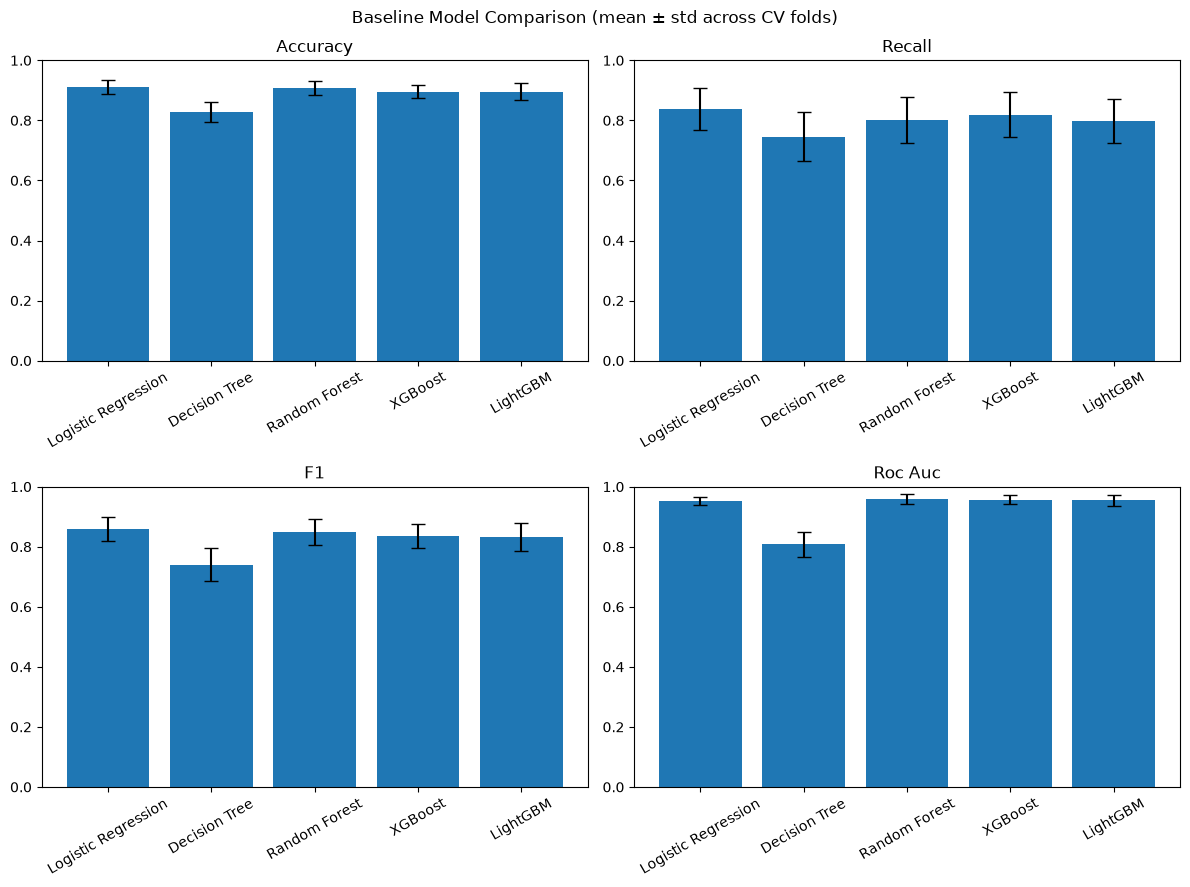

In [63]:
metrics_to_plot = ['accuracy', 'recall', 'f1', 'roc_auc']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

for ax, metric in zip(axes, metrics_to_plot):
    means = baseline_results_df[f'{metric}_mean']
    stds = baseline_results_df[f'{metric}_std']
    ax.bar(baseline_results_df['Model'], means, yerr=stds, capsize=5)
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Baseline Model Comparison (mean ± std across CV folds)')
plt.tight_layout()
plt.show()


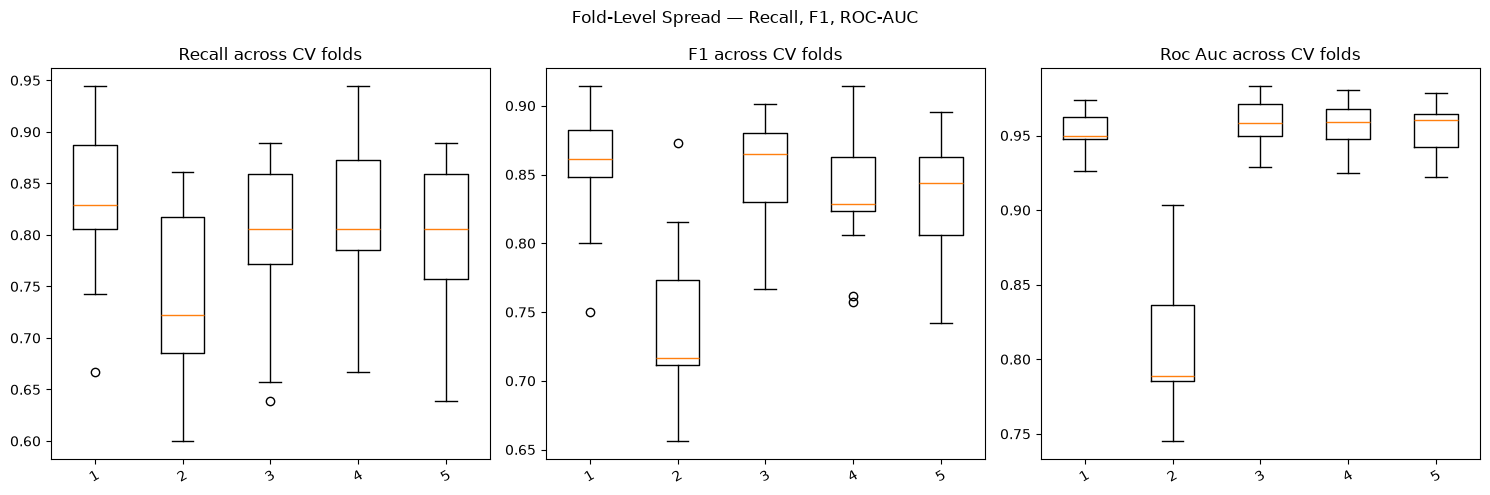

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, ['recall', 'f1', 'roc_auc']):
    fold_scores = get_cv_results(baseline_raw_results, metric)
    ax.boxplot(fold_scores.values)
    ax.set_title(f'{metric.replace("_", " ").title()} across CV folds')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Fold-Level Spread — Recall, F1, ROC-AUC')
plt.tight_layout()
plt.show()


Answering the Comparison Questions

In [65]:
for metric in ['accuracy', 'recall', 'f1', 'roc_auc']:
    best_row = baseline_results_df.loc[baseline_results_df[f'{metric}_mean'].idxmax()]
    print(f"Highest {metric.replace('_', ' ').title():<10}: {best_row['Model']:<20} "
          f"({best_row[f'{metric}_mean']:.4f} ± {best_row[f'{metric}_std']:.4f})")


Highest Accuracy  : Logistic Regression  (0.9100 ± 0.0228)
Highest Recall    : Logistic Regression  (0.8381 ± 0.0704)
Highest F1        : Logistic Regression  (0.8580 ± 0.0402)
Highest Roc Auc   : Random Forest        (0.9593 ± 0.0158)


Class Imbalance Check


In [66]:
class_counts = y.value_counts()
class_ratio = class_counts.min() / class_counts.max()

print("Class counts:")
print(class_counts)
print(f"\nMinority : Majority ratio = {class_ratio:.2f} (1.00 = perfectly balanced)")


Class counts:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

Minority : Majority ratio = 0.49 (1.00 = perfectly balanced)


## 5. Feature costs and methodological diagnostics

Feature Cost Categorization

In [67]:
feature_cost_groups = {
    'Free / Low Cost': [
        'Age (yrs)', 'BMI', 'Waist:Hip Ratio',
        'Cycle(R/I)', 'Cycle length(days)',
        'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
        'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)'
    ],
    'Medium Cost': [
        'Vit D3 (ng/mL)'
    ],
    'High Cost (Hormonal Labs)': [
        'FSH(mIU/mL)', 'LH(mIU/mL)', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'PRG(ng/mL)'
    ],
    'Very High Cost (Ultrasound)': [
        'Follicle No. (L)', 'Follicle No. (R)',
        'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)'
    ]
}

all_grouped = sum(feature_cost_groups.values(), [])

named_but_missing = [c for c in all_grouped if c not in X.columns]
present_but_ungrouped = [c for c in X.columns if c not in all_grouped]

print("Named in a group but NOT found in X.columns (fix the spelling/spacing):")
print(named_but_missing if named_but_missing else "  None — good.")

print("\nPresent in X but not yet assigned to a group (decide where these belong):")
print(present_but_ungrouped if present_but_ungrouped else "  None — every column is grouped.")

print("\nProposed feature cost groups:")
for group, cols in feature_cost_groups.items():
    print(f"\n{group} ({len(cols)} features):")
    for c in cols:
        print(f"  - {c}")


Named in a group but NOT found in X.columns (fix the spelling/spacing):
['Age (yrs)']

Present in X but not yet assigned to a group (decide where these belong):
[' Age (yrs)']

Proposed feature cost groups:

Free / Low Cost (12 features):
  - Age (yrs)
  - BMI
  - Waist:Hip Ratio
  - Cycle(R/I)
  - Cycle length(days)
  - Weight gain(Y/N)
  - hair growth(Y/N)
  - Skin darkening (Y/N)
  - Hair loss(Y/N)
  - Pimples(Y/N)
  - Fast food (Y/N)
  - Reg.Exercise(Y/N)

Medium Cost (1 features):
  - Vit D3 (ng/mL)

High Cost (Hormonal Labs) (6 features):
  - FSH(mIU/mL)
  - LH(mIU/mL)
  - TSH (mIU/L)
  - AMH(ng/mL)
  - PRL(ng/mL)
  - PRG(ng/mL)

Very High Cost (Ultrasound) (5 features):
  - Follicle No. (L)
  - Follicle No. (R)
  - Avg. F size (L) (mm)
  - Avg. F size (R) (mm)
  - Endometrium (mm)


**Reasoning behind each tier:**

- **Free / Low Cost** — age, BMI, and the Y/N symptom/lifestyle questions are all things a patient can report or that require no lab work at all: zero marginal cost per screening.
- **Medium Cost** — Vitamin D3 is a common, relatively inexpensive standalone blood test (and its outlier flag travels with it), distinct from the specialized hormonal panel below.
- **High Cost (Hormonal Labs)** — FSH, LH, TSH, AMH, Prolactin, and Progesterone all require a dedicated hormonal assay panel, generally pricier and slower-turnaround than routine bloodwork. The corresponding outlier flags are grouped with their source feature, since dropping the feature makes the flag meaningless too.
- **Very High Cost (Ultrasound)** — follicle counts, follicle size, and endometrial thickness all require a transvaginal/pelvic ultrasound with a trained sonographer — the most expensive and least accessible data in the set, and the main target of the ablation question in your project goal.


In [68]:
print("df_model shape:", df_model.shape)
print("X shape:", X.shape)

outlier_flag_cols = ['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']
in_df = [c for c in outlier_flag_cols if c in df_model.columns]
in_X = [c for c in outlier_flag_cols if c in X.columns]

print("\nOutlier flag columns still in df_model:", in_df if in_df else "None — confirmed removed")
print("Outlier flag columns still in X:", in_X if in_X else "None — confirmed removed")

print(f"\nPredictor columns in X ({X.shape[1]} total):")
for c in X.columns:
    print(" -", c)

print("\nIs the target column present anywhere in X?:", target_col in X.columns)


df_model shape: (541, 25)
X shape: (541, 24)

Outlier flag columns still in df_model: None — confirmed removed
Outlier flag columns still in X: None — confirmed removed

Predictor columns in X (24 total):
 -  Age (yrs)
 - BMI
 - Cycle(R/I)
 - Cycle length(days)
 - FSH(mIU/mL)
 - LH(mIU/mL)
 - Waist:Hip Ratio
 - TSH (mIU/L)
 - AMH(ng/mL)
 - PRL(ng/mL)
 - Vit D3 (ng/mL)
 - PRG(ng/mL)
 - Weight gain(Y/N)
 - hair growth(Y/N)
 - Skin darkening (Y/N)
 - Hair loss(Y/N)
 - Pimples(Y/N)
 - Fast food (Y/N)
 - Reg.Exercise(Y/N)
 - Follicle No. (L)
 - Follicle No. (R)
 - Avg. F size (L) (mm)
 - Avg. F size (R) (mm)
 - Endometrium (mm)

Is the target column present anywhere in X?: False


In [69]:
from sklearn.metrics import roc_auc_score

univariate_rows = []
for col in X.columns:
    valid = X[col].notna()
    if valid.sum() < 10:
        continue
    corr = np.corrcoef(X.loc[valid, col], y.loc[valid])[0, 1]
    try:
        auc = roc_auc_score(y.loc[valid], X.loc[valid, col])
        auc = max(auc, 1 - auc)
    except ValueError:
        auc = np.nan
    univariate_rows.append({
        'feature': col,
        'corr_with_target': corr,
        'single_feature_auc': auc,
        'n_valid': int(valid.sum())
    })

univariate_df = pd.DataFrame(univariate_rows).sort_values('single_feature_auc', ascending=False).reset_index(drop=True)
univariate_df


,feature,corr_with_target,single_feature_auc,n_valid
0,Follicle No. (R),0.648327,0.885190,541
1,Follicle No. (L),0.603346,0.856049,541
2,Skin darkening (Y/N),0.475733,0.733811,541
3,Weight gain(Y/N),0.441047,0.727797,541
4,hair growth(Y/N),0.464667,0.720750,541
5,Fast food (Y/N),0.377933,0.701195,540
6,Cycle(R/I),0.397917,0.690122,540
7,Pimples(Y/N),0.286077,0.652403,541
8,Cycle length(days),-0.184732,0.644519,540
9,AMH(ng/mL),0.236806,0.631986,528


In [70]:
SUSPICIOUS_AUC_THRESHOLD = 0.85
SUSPICIOUS_CORR_THRESHOLD = 0.60

suspicious_univariate = univariate_df[
    (univariate_df['single_feature_auc'] > SUSPICIOUS_AUC_THRESHOLD) |
    (univariate_df['corr_with_target'].abs() > SUSPICIOUS_CORR_THRESHOLD)
]

print(f"Features flagged as suspiciously predictive on their own "
      f"(single-feature AUC > {SUSPICIOUS_AUC_THRESHOLD} or |corr| > {SUSPICIOUS_CORR_THRESHOLD}):")
suspicious_univariate


Features flagged as suspiciously predictive on their own (single-feature AUC > 0.85 or |corr| > 0.6):


,feature,corr_with_target,single_feature_auc,n_valid
0,Follicle No. (R),0.648327,0.885190,541
1,Follicle No. (L),0.603346,0.856049,541


Correlation among predictors

In [71]:
corr_matrix = X.corr(numeric_only=True)

HIGH_CORR_THRESHOLD = 0.85
high_corr_pairs = []
cols = corr_matrix.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > HIGH_CORR_THRESHOLD:
            high_corr_pairs.append((cols[i], cols[j], r))

high_corr_df = pd.DataFrame(high_corr_pairs, columns=['feature_1', 'feature_2', 'correlation'])
if len(high_corr_df):
    high_corr_df = high_corr_df.reindex(high_corr_df['correlation'].abs().sort_values(ascending=False).index)
print(f"Predictor pairs with |correlation| > {HIGH_CORR_THRESHOLD}:")
high_corr_df


Predictor pairs with |correlation| > 0.85:


,feature_1,feature_2,correlation


In [72]:
print("Target column present in X:", target_col in X.columns, "(should be False)")

print("\nPipeline steps per model:")
for name, pipeline in models.items():
    print(f"  {name}: {[step[0] for step in pipeline.steps]}")

print("\nTotal missing values still present in X (should be > 0 -- proves imputation")
print("has NOT been applied to X outside the pipeline):", int(X.isnull().sum().sum()))

print("\nRaw feature scale check (mean/std should NOT already look standardized to ~0/~1 --")
print("proves scaling has NOT been pre-applied to X):")
X.describe().T[['mean', 'std']]


Target column present in X: False (should be False)

Pipeline steps per model:
  Logistic Regression: ['imputer', 'scaler', 'clf']
  Decision Tree: ['imputer', 'clf']
  Random Forest: ['imputer', 'clf']
  XGBoost: ['imputer', 'clf']
  LightGBM: ['imputer', 'clf']

Total missing values still present in X (should be > 0 -- proves imputation
has NOT been applied to X outside the pipeline): 31

Raw feature scale check (mean/std should NOT already look standardized to ~0/~1 --
proves scaling has NOT been pre-applied to X):


,mean,std
Age (yrs),31.430684,5.411006
BMI,24.311285,4.056399
Cycle(R/I),2.555556,0.896637
Cycle length(days),4.950000,1.478134
FSH(mIU/mL),5.273317,4.489391
LH(mIU/mL),2.744863,2.307678
Waist:Hip Ratio,0.891895,0.046326
TSH (mIU/L),2.981281,3.755532
AMH(ng/mL),5.118869,4.536297
PRL(ng/mL),24.321497,14.970391


Confirm identical CV splits were used across all five models


In [73]:
splits_call_1 = list(cv.split(X, y))
splits_call_2 = list(cv.split(X, y))

identical = all(
    np.array_equal(a_train, b_train) and np.array_equal(a_test, b_test)
    for (a_train, a_test), (b_train, b_test) in zip(splits_call_1, splits_call_2)
)

print("Are cv.split(X, y) results identical across repeated calls?:", identical)
print("Number of train/test splits produced:", len(splits_call_1), "(expected: 5 folds x 3 repeats = 15)")


Are cv.split(X, y) results identical across repeated calls?: True
Number of train/test splits produced: 15 (expected: 5 folds x 3 repeats = 15)


Duplicate or near-duplicate patient records

In [74]:
exact_dupes = df_model.duplicated().sum()
feature_only_dupes = X.duplicated().sum()
near_dupes_rounded = X.round(1).duplicated().sum()

print("Exact duplicate rows in df_model (features + target):", exact_dupes)
print("Rows with identical feature values, ignoring the target:", feature_only_dupes)
print("Near-duplicate rows after rounding numeric features to 1 decimal:", near_dupes_rounded)


Exact duplicate rows in df_model (features + target): 0
Rows with identical feature values, ignoring the target: 0
Near-duplicate rows after rounding numeric features to 1 decimal: 0


Individual cross-validation fold scores


In [75]:
for metric in ['accuracy', 'recall', 'f1', 'roc_auc']:
    print(f"\n{metric.upper()} — all 15 fold scores per model:")
    display(get_cv_results(baseline_raw_results, metric).round(4))



ACCURACY — all 15 fold scores per model:


,Logistic Regression,Decision Tree,Random Forest,XGBoost,LightGBM
0,0.9358,0.9174,0.9266,0.9083,0.9083
1,0.8796,0.7778,0.8981,0.8519,0.8426
2,0.9444,0.8241,0.8981,0.9444,0.9352
3,0.9074,0.8241,0.9259,0.8889,0.9074
4,0.9167,0.8426,0.8704,0.8889,0.9074
5,0.9266,0.8073,0.9083,0.9083,0.8991
6,0.8889,0.8519,0.9352,0.8889,0.8981
7,0.9259,0.8056,0.9167,0.8889,0.8981
8,0.9259,0.7963,0.9259,0.9352,0.9352
9,0.8519,0.8426,0.8704,0.8611,0.8519



RECALL — all 15 fold scores per model:


,Logistic Regression,Decision Tree,Random Forest,XGBoost,LightGBM
0,0.8889,0.8611,0.8611,0.8889,0.8611
1,0.7429,0.7143,0.7714,0.7143,0.7429
2,0.9143,0.6857,0.8286,0.9143,0.8571
3,0.8857,0.7714,0.8000,0.8000,0.7714
4,0.8056,0.7778,0.7222,0.8056,0.7778
5,0.9444,0.7222,0.8889,0.9167,0.8889
6,0.8286,0.8571,0.8571,0.8000,0.8000
7,0.8857,0.6571,0.8571,0.8000,0.8286
8,0.8286,0.6000,0.8000,0.8286,0.8286
9,0.6667,0.6667,0.6389,0.6667,0.6389



F1 — all 15 fold scores per model:


,Logistic Regression,Decision Tree,Random Forest,XGBoost,LightGBM
0,0.9014,0.8732,0.8857,0.8649,0.8611
1,0.8000,0.6757,0.8308,0.7576,0.7536
2,0.9143,0.7164,0.8406,0.9143,0.8955
3,0.8611,0.7397,0.8750,0.8235,0.8438
4,0.8657,0.7671,0.7879,0.8286,0.8485
5,0.8947,0.7123,0.8649,0.8684,0.8533
6,0.8286,0.7895,0.8955,0.8235,0.8358
7,0.8857,0.6866,0.8696,0.8235,0.8406
8,0.8788,0.6562,0.8750,0.8923,0.8923
9,0.7500,0.7385,0.7667,0.7619,0.7419



ROC_AUC — all 15 fold scores per model:


,Logistic Regression,Decision Tree,Random Forest,XGBoost,LightGBM
0,0.9475,0.9032,0.9427,0.9509,0.9498
1,0.9479,0.7613,0.9481,0.9335,0.9225
2,0.9487,0.7881,0.9583,0.9710,0.9718
3,0.9562,0.8104,0.9746,0.9699,0.9652
4,0.9522,0.8264,0.9664,0.9688,0.9637
5,0.9669,0.7858,0.9656,0.9616,0.9543
6,0.9264,0.8532,0.9546,0.9468,0.9538
7,0.9581,0.7669,0.9509,0.9589,0.9605
8,0.9695,0.7452,0.9832,0.9675,0.9789
9,0.9498,0.7986,0.9570,0.9464,0.9352


overfitting check

In [76]:
diagnostic_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)  # same config as `cv`, kept separate

overfit_rows = []
for name, pipeline in models.items():
    res = cross_validate(
        pipeline, X, y, cv=diagnostic_cv,
        scoring=['accuracy', 'roc_auc'],
        return_train_score=True,
        n_jobs=-1
    )
    overfit_rows.append({
        'Model': name,
        'Train Accuracy': res['train_accuracy'].mean(),
        'Val Accuracy': res['test_accuracy'].mean(),
        'Accuracy Gap': res['train_accuracy'].mean() - res['test_accuracy'].mean(),
        'Train ROC-AUC': res['train_roc_auc'].mean(),
        'Val ROC-AUC': res['test_roc_auc'].mean(),
        'ROC-AUC Gap': res['train_roc_auc'].mean() - res['test_roc_auc'].mean(),
    })

overfit_summary = pd.DataFrame(overfit_rows)
overfit_summary.round(4)


BrokenProcessPool: A task has failed to un-serialize. Please ensure that the arguments of the function are all picklable.

Is class imbalance inflating Accuracy?


In [ ]:
from sklearn.dummy import DummyClassifier

dummy_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', DummyClassifier(strategy='most_frequent', random_state=42))
])

dummy_results = evaluate_model(dummy_pipe, X, y, cv, scoring)

print("Majority-class baseline (predicts the majority class every time, no real signal used):")
for metric in ['accuracy', 'recall', 'f1', 'roc_auc']:
    scores = dummy_results[f'test_{metric}']
    print(f"  {metric:<10}: {scores.mean():.4f} ± {scores.std():.4f}")


Out-of-fold confusion matrix


In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = cross_val_predict(pipe_lr, X, y, cv=cv_oof, method='predict', n_jobs=-1)

cm = confusion_matrix(y, oof_preds)
ConfusionMatrixDisplay(cm, display_labels=['No PCOS', 'PCOS']).plot(cmap='Blues')
plt.title('Logistic Regression -- Out-of-Fold Confusion Matrix (single-pass 5-fold)')
plt.show()

print(cm)


## 6. Cost ablation and diagnostic-overlap sensitivity analysis

Cost-Based Feature Ablation


In [ ]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


Resolving the Final Feature Set


In [ ]:
outlier_flag_cols = ['FSH_outlier', 'LH_outlier', 'AMH_outlier', 'VitD_outlier']
print("Outlier flag columns present in X:", [c for c in outlier_flag_cols if c in X.columns] or "None — confirmed absent")

print(f"\nFinal feature count: {X.shape[1]}")
print("Final feature names:")
for c in X.columns:
    print(" -", c)

print(f"\nTarget column: {target_col}")
print("Target distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

print("\nMissing values per feature (handled inside the pipeline, not here):")
missing = X.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))


Clinical Circularity: Primary Analysis vs. Sensitivity Analysis



In [ ]:
criterion_overlap_features = [
    'Cycle(R/I)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
    'Follicle No. (L)', 'Follicle No. (R)',
    'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)'
]
criterion_overlap_features = [c for c in criterion_overlap_features if c in X.columns]
print("Criterion-overlap features confirmed present in X:", criterion_overlap_features)

cv_ablation = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

X_primary_full = X.copy()
X_sensitivity_full = X.drop(columns=criterion_overlap_features)

print(f"\nPrimary full feature count: {X_primary_full.shape[1]}")
print(f"Sensitivity full feature count (criterion-overlap removed): {X_sensitivity_full.shape[1]}")


In [ ]:
print("Running PRIMARY full-feature evaluation (n_repeats=10)...")
primary_full_results_df, primary_full_raw = evaluate_all_models(
    models, X_primary_full, y, cv_ablation, scoring, feature_set_name='A0_full'
)

print("\nRunning SENSITIVITY full-feature evaluation (criterion-overlap excluded)...")
sensitivity_full_results_df, sensitivity_full_raw = evaluate_all_models(
    models, X_sensitivity_full, y, cv_ablation, scoring, feature_set_name='A0_full_sensitivity'
)

primary_vs_sensitivity = pd.concat([
    format_mean_std_table(primary_full_results_df).assign(Analysis='Primary (full)'),
    format_mean_std_table(sensitivity_full_results_df).assign(Analysis='Sensitivity (criterion-overlap removed)')
], ignore_index=True)

primary_vs_sensitivity = primary_vs_sensitivity[['Analysis', 'Model'] + [c for c in primary_vs_sensitivity.columns if c not in ('Analysis', 'Model')]]
primary_vs_sensitivity


Feature Cost Tiers

In [ ]:
cost_tiers = {
    'Free / Low Cost': [
        ' Age (yrs)', 'BMI', 'Waist:Hip Ratio',
        'Cycle(R/I)', 'Cycle length(days)',
        'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
        'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)'
    ],
    'Medium Cost': [
        'Vit D3 (ng/mL)'
    ],
    'High Cost (Hormonal Labs)': [
        'FSH(mIU/mL)', 'LH(mIU/mL)', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'PRG(ng/mL)'
    ],
    'Very High Cost (Ultrasound)': [
        'Follicle No. (L)', 'Follicle No. (R)',
        'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)'
    ]
}

all_tiered = sum(cost_tiers.values(), [])
named_but_missing = [c for c in all_tiered if c not in X.columns]
present_but_untiered = [c for c in X.columns if c not in all_tiered]
print("Named in a tier but not found in X:", named_but_missing or "None")
print("Present in X but not yet tiered:", present_but_untiered or "None — every feature is tiered")

feature_cost_table = pd.DataFrame(
    [(tier, feat) for tier, feats in cost_tiers.items() for feat in feats],
    columns=['Cost Tier', 'Feature']
)
feature_cost_table


The Ablation Ladder


In [ ]:
free_low = cost_tiers['Free / Low Cost']
medium = cost_tiers['Medium Cost']
high = cost_tiers['High Cost (Hormonal Labs)']
very_high = cost_tiers['Very High Cost (Ultrasound)']

ablation_stages = {
    'A0_full':               free_low + medium + high + very_high,
    'A1_no_very_high':       free_low + medium + high,
    'A2_no_very_high_high':  free_low + medium,
    'A3_low_medium':         free_low + medium,
    'A4_low_only':           free_low,
}

cost_level_map = {
    'A0_full': 'Full (All Tiers)',
    'A1_no_very_high': 'Without Very-High',
    'A2_no_very_high_high': 'Without Very-High + High',
    'A3_low_medium': 'Low + Medium Only',
    'A4_low_only': 'Low-Cost Only',
}

for stage, feats in ablation_stages.items():
    print(f"{stage} ({cost_level_map[stage]}): {len(feats)} features")
    print(" ", feats)
    print()

print("A2 and A3 identical as expected?:", set(ablation_stages['A2_no_very_high_high']) == set(ablation_stages['A3_low_medium']))


Evaluating All Five Models at Every Ablation Stage, Eventually building the Master Results Table

In [ ]:
ablation_master_frames = [primary_full_results_df]
ablation_raw_results = {'A0_full': primary_full_raw}

for stage_name, feat_list in ablation_stages.items():
    if stage_name == 'A0_full':
        continue
    print(f"=== Evaluating stage: {stage_name} ({len(feat_list)} features) ===")
    X_stage = X[feat_list]
    results_df, raw_results = evaluate_all_models(models, X_stage, y, cv_ablation, scoring, feature_set_name=stage_name)
    ablation_master_frames.append(results_df)
    ablation_raw_results[stage_name] = raw_results

ablation_master_df = pd.concat(ablation_master_frames, ignore_index=True)
ablation_master_df['cost_level'] = ablation_master_df['Feature Set'].map(cost_level_map)
ablation_master_df = ablation_master_df.rename(columns={'Model': 'model', 'Feature Set': 'feature_set'})

front_cols = ['feature_set', 'cost_level', 'model']
metric_cols = [c for c in ablation_master_df.columns if c not in front_cols]
ablation_master_df = ablation_master_df[front_cols + metric_cols]

ablation_master_df.round(4)


Performance Retention Relative to A0 (Full)

In [ ]:
def compute_retention(master_df, baseline_stage='A0_full', metrics=('accuracy', 'recall', 'f1', 'roc_auc')):
    baseline = master_df[master_df['feature_set'] == baseline_stage].set_index('model')
    rows = []
    for stage in master_df['feature_set'].unique():
        if stage == baseline_stage:
            continue
        stage_df = master_df[master_df['feature_set'] == stage].set_index('model')
        for model_name in stage_df.index:
            row = {'feature_set': stage, 'cost_level': cost_level_map[stage], 'model': model_name}
            for metric in metrics:
                base_val = baseline.loc[model_name, f'{metric}_mean']
                stage_val = stage_df.loc[model_name, f'{metric}_mean']
                abs_change = stage_val - base_val
                pct_change = (abs_change / base_val) * 100 if base_val != 0 else np.nan
                pct_retained = (stage_val / base_val) * 100 if base_val != 0 else np.nan
                row[f'{metric}_abs_change'] = abs_change
                row[f'{metric}_pct_change'] = pct_change
                row[f'{metric}_pct_retained'] = pct_retained
            rows.append(row)
    return pd.DataFrame(rows)

retention_df = compute_retention(ablation_master_df)
retention_df.round(3)


In [ ]:
stage_order = ['A0_full', 'A1_no_very_high', 'A2_no_very_high_high', 'A3_low_medium', 'A4_low_only']
metrics_to_plot = ['accuracy', 'recall', 'f1', 'roc_auc']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

for ax, metric in zip(axes, metrics_to_plot):
    for model_name in models.keys():
        model_data = ablation_master_df[ablation_master_df['model'] == model_name].set_index('feature_set').reindex(stage_order)
        ax.errorbar(
            stage_order, model_data[f'{metric}_mean'], yerr=model_data[f'{metric}_std'],
            marker='o', capsize=3, label=model_name
        )
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.05))
plt.suptitle('Model Performance by Ablation Stage', y=1.08)
plt.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

for model_name in models.keys():
    model_retention = retention_df[retention_df['model'] == model_name].set_index('feature_set').reindex(
        [s for s in stage_order if s != 'A0_full']
    )
    ax.plot(model_retention.index, model_retention['roc_auc_pct_retained'], marker='o', label=model_name)

ax.axhline(100, color='gray', linestyle='--', linewidth=1, label='A0 full-feature level')
ax.set_ylabel('% of Full-Feature ROC-AUC Retained')
ax.set_title('Performance Retention Curve (ROC-AUC)')
ax.tick_params(axis='x', rotation=30)
ax.legend()
plt.tight_layout()
plt.show()


## Descriptive paired fold differences (exploratory)
Overlapping repeated folds are dependent. No Wilcoxon p-values or equivalence
decisions are computed. Use model_evaluation.ipynb for nested evaluation.

In [ ]:
comparison_stages = ['A1_no_very_high', 'A2_no_very_high_high', 'A4_low_only']
key_metrics = ['roc_auc', 'recall', 'f1']
paired_fold_rows = []
for model_name in models:
    for stage in comparison_stages:
        for metric in key_metrics:
            a = np.asarray(ablation_raw_results['A0_full'][model_name]['test_' + metric])
            b = np.asarray(ablation_raw_results[stage][model_name]['test_' + metric])
            paired_fold_rows.append({'model': model_name, 'stage': stage, 'metric': metric,
                                     'reference': 'A0_full, same algorithm',
                                     'mean_difference_reduced_minus_full': float((b-a).mean()),
                                     'fold_difference_sd': float((b-a).std()),
                                     'interpretation': 'Descriptive only; dependent folds; no equivalence claim'})
paired_fold_df = pd.DataFrame(paired_fold_rows)
paired_fold_df.round(4)

Identify the Best Low-Cost Model


In [ ]:
def rank_models(master_df, feature_set, metrics_priority=('recall', 'f1', 'roc_auc', 'accuracy')):
    stage_df = master_df[master_df['feature_set'] == feature_set].copy()
    sort_cols = [f'{m}_mean' for m in metrics_priority]
    return stage_df.sort_values(sort_cols, ascending=False)[['model'] + sort_cols]

print("Best full-feature model (A0), ranked by Recall > F1 > ROC-AUC > Accuracy:")
best_full_ranking = rank_models(ablation_master_df, 'A0_full')
display(best_full_ranking)
best_full_model = best_full_ranking.iloc[0]['model']
print(f"\n--> Best full-feature model: {best_full_model}")


In [ ]:
print("Best model at every ablation stage:\n")
for stage in stage_order:
    ranking = rank_models(ablation_master_df, stage)
    top = ranking.iloc[0]
    print(f"{stage} ({cost_level_map[stage]}): {top['model']} "
          f"(Recall={top['recall_mean']:.3f}, F1={top['f1_mean']:.3f}, ROC-AUC={top['roc_auc_mean']:.3f})")


In [ ]:
print('No statistically equivalent or noninferior low-cost stage has been established.')
print('Repeated-fold differences are descriptive. Nonsignificance is not equivalence.')
print('Use the separate nested workflow for consistent procedure-level comparisons.')

SHAP: Which Affordable Features Still Carry Signal?


Sensitivity Analysis


In [ ]:
sensitivity_stages = {
    stage: [f for f in feats if f not in criterion_overlap_features]
    for stage, feats in ablation_stages.items()
}

for stage, feats in sensitivity_stages.items():
    print(f"{stage} (sensitivity): {len(feats)} features -- removed: "
          f"{[f for f in ablation_stages[stage] if f not in feats]}")


In [ ]:
sensitivity_master_frames = [sensitivity_full_results_df.rename(columns={'Model': 'Model'})]
sensitivity_raw_results = {'A0_full': sensitivity_full_raw}

for stage_name, feat_list in sensitivity_stages.items():
    if stage_name == 'A0_full':
        continue
    if set(feat_list) == set(sensitivity_stages.get('A0_full', [])):
        pass
    print(f"=== Evaluating SENSITIVITY stage: {stage_name} ({len(feat_list)} features) ===")
    X_stage = X[feat_list]
    results_df, raw_results = evaluate_all_models(models, X_stage, y, cv_ablation, scoring, feature_set_name=f'{stage_name}_sensitivity')
    sensitivity_master_frames.append(results_df)
    sensitivity_raw_results[stage_name] = raw_results

sensitivity_master_df = pd.concat(sensitivity_master_frames, ignore_index=True)
sensitivity_master_df['cost_level'] = sensitivity_master_df['Feature Set'].str.replace('_sensitivity', '', regex=False).map(cost_level_map)
sensitivity_master_df = sensitivity_master_df.rename(columns={'Model': 'model', 'Feature Set': 'feature_set'})
sensitivity_master_df.round(4)


In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

for model_name in models.keys():
    primary_line = ablation_master_df[ablation_master_df['model'] == model_name].set_index('feature_set').reindex(stage_order)
    ax.plot(stage_order, primary_line['roc_auc_mean'], marker='o', linestyle='-', label=f'{model_name} (Primary)', alpha=0.9)

sens_stage_order = [f'{s}_sensitivity' for s in stage_order]
for model_name in models.keys():
    sens_line = sensitivity_master_df[sensitivity_master_df['model'] == model_name].set_index('feature_set').reindex(sens_stage_order)
    ax.plot(stage_order, sens_line['roc_auc_mean'].values, marker='x', linestyle='--', label=f'{model_name} (Sensitivity)', alpha=0.6)

ax.set_ylabel('ROC-AUC')
ax.set_title('Primary vs. Sensitivity Analysis: ROC-AUC Across Ablation Stages')
ax.tick_params(axis='x', rotation=30)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


Tables and Figures


In [ ]:
print("TABLE 1 -- Final Dataset / Features")
table_1 = pd.DataFrame({'Feature': X.columns, 'Cost Tier': [
    next(tier for tier, feats in cost_tiers.items() if f in feats) for f in X.columns
]})
table_1


In [ ]:
print("TABLE 2 -- Feature Cost Tiers")
feature_cost_table


In [ ]:
print("TABLE 3 -- Full-Feature Baseline Performance (A0, Primary)")
format_mean_std_table(primary_full_results_df)


In [ ]:
print("TABLE 4 -- Ablation Performance (All Stages, All Models)")
ablation_master_df.round(4)


In [ ]:
print("TABLE 5 -- Performance Retention / Degradation Relative to A0")
retention_df.round(3)


In [ ]:
print('TABLE 6 -- Descriptive paired fold differences; no inferential p-values')
paired_fold_df.round(4)

In [ ]:
print('TABLE 7 -- Exploratory full-feature and prespecified low-cost candidates')
best_full_model_final = rank_models(ablation_master_df, 'A0_full').iloc[0]['model']
low_cost_model_final = rank_models(ablation_master_df, 'A4_low_only').iloc[0]['model']
table_7 = pd.concat([
    ablation_master_df[(ablation_master_df.feature_set == 'A0_full') &
                       (ablation_master_df.model == best_full_model_final)],
    ablation_master_df[(ablation_master_df.feature_set == 'A4_low_only') &
                       (ablation_master_df.model == low_cost_model_final)]
], ignore_index=True)
print('Candidates selected and described on the same CV: exploratory, not unbiased performance.')
print('A4 was chosen as a comparison group, not proven equivalent or cost-effective.')
table_7

## 7. Original model comparison and findings

Per-Stage Model Comparison --- Bar Charts & Fold Spread (A0, A1, A2, A3)

In [ ]:
def plot_stage_bar_comparison(stage_name, master_df, title_prefix=None):
    """Bar chart (mean +/- std across CV folds) for one ablation stage."""
    stage_df = master_df[master_df['feature_set'] == stage_name].reset_index(drop=True)
    metrics_to_plot = ['accuracy', 'recall', 'f1', 'roc_auc']

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics_to_plot):
        means = stage_df[f'{metric}_mean']
        stds = stage_df[f'{metric}_std']
        ax.bar(stage_df['model'], means, yerr=stds, capsize=5)
        ax.set_title(metric.replace('_', ' ').title())
        ax.set_ylim(0, 1)
        ax.tick_params(axis='x', rotation=30)

    label = title_prefix or f'{stage_name} ({cost_level_map[stage_name]})'
    plt.suptitle(f'Model Comparison -- {label} (mean ± std across CV folds)')
    plt.tight_layout()
    plt.show()


all_stages_to_plot = ['A0_full', 'A1_no_very_high', 'A2_no_very_high_high', 'A3_low_medium']

for stage in all_stages_to_plot:
    plot_stage_bar_comparison(stage, ablation_master_df)

In [ ]:
def plot_stage_fold_spread(stage_name, raw_results_dict, title_prefix=None):
    """Fold-level boxplot (Recall, F1, ROC-AUC) for one ablation stage."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, metric in zip(axes, ['recall', 'f1', 'roc_auc']):
        fold_scores = get_cv_results(raw_results_dict[stage_name], metric)
        ax.boxplot(fold_scores.values, tick_labels=fold_scores.columns)
        ax.set_title(f'{metric.replace("_", " ").title()} across CV folds')
        ax.tick_params(axis='x', rotation=30)

    label = title_prefix or f'{stage_name} ({cost_level_map[stage_name]})'
    plt.suptitle(f'Fold-Level Spread -- {label}')
    plt.tight_layout()
    plt.show()


for stage in all_stages_to_plot:
    plot_stage_fold_spread(stage, ablation_raw_results)

In [ ]:
plot_stage_bar_comparison('A4_low_only', ablation_master_df)

In [ ]:
plot_stage_fold_spread('A4_low_only', ablation_raw_results)

generated from the calculated results above

In [ ]:
print('EXPLORATORY CANDIDATES ONLY')
display(table_7)
print('No cheapest acceptable or cost-effective winner is selected.')
print('These repeated-CV candidate summaries reuse selection data.')
print('See model_evaluation.ipynb for nested outer-fold estimates.')

Findings



In [ ]:
print('REPORT CHECKS')
print('Rows:', len(df_model))
print('Predictor features:', X.shape[1])
print('Target distribution:', y.value_counts().to_dict())
print('Descriptive paired comparisons:', len(paired_fold_df))
print('Legacy candidate analysis remains exploratory; no repeated-fold significance test.')

## 8. Hybrid modelling and probability evaluation

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.metrics import make_scorer, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from IPython.display import display

hybrid_required = ['X', 'y', 'models', 'cv_ablation', 'scoring',
                   'ablation_stages', 'sensitivity_stages', 'ablation_raw_results',
                   'sensitivity_raw_results', 'cost_level_map']
hybrid_missing = [name for name in hybrid_required if name not in globals()]
if hybrid_missing:
    raise RuntimeError('Run the original notebook first. Missing: ' + ', '.join(hybrid_missing))
assert 'PCOS (Y/N)' not in X.columns
assert set(y.unique()) == {0, 1}
assert len(X) == len(y) and X.index.equals(y.index)
hybrid_splits = list(cv_ablation.split(X, y))
hybrid_inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hybrid_estimators = {
    'RF + LR Stacking': StackingClassifier(
        estimators=[('rf', clone(models['Random Forest'])),
                    ('lr', clone(models['Logistic Regression']))],
        final_estimator=LogisticRegression(max_iter=2000, random_state=42),
        stack_method='predict_proba', passthrough=False,
        cv=hybrid_inner_cv, n_jobs=1),
    'RF + LR Soft Voting': VotingClassifier(
        estimators=[('rf', clone(models['Random Forest'])),
                    ('lr', clone(models['Logistic Regression']))],
        voting='soft', weights=[1, 1], n_jobs=1)
}
hybrid_all_models = {name: clone(est) for name, est in models.items()}
hybrid_all_models.update(hybrid_estimators)
hybrid_n_jobs = 1  
print('Models:', list(hybrid_all_models))
print('Outer folds:', len(hybrid_splits), '| internal stacking folds: 5')

## Evaluate both hybrids at every cost stage and sensitivity stage

In [ ]:
if 'hybrid_cv_cache' not in globals():
    hybrid_cv_cache = {}
hybrid_raw_by_analysis = {}
hybrid_summary_rows = []
for hybrid_analysis, hybrid_stages, hybrid_legacy in [
    ('Primary', ablation_stages, ablation_raw_results),
    ('Sensitivity', sensitivity_stages, sensitivity_raw_results)
]:
    hybrid_raw_by_analysis[hybrid_analysis] = {}
    for hybrid_stage, hybrid_features in hybrid_stages.items():
        hybrid_stage_raw = {}
        for hybrid_name in models:
            hybrid_existing = hybrid_legacy[hybrid_stage][hybrid_name]
            if any(len(hybrid_existing['test_' + m]) != len(hybrid_splits) for m in scoring):
                raise ValueError('Legacy results do not match the outer fold count.')
            hybrid_stage_raw[hybrid_name] = hybrid_existing
        for hybrid_name, hybrid_est in hybrid_estimators.items():
            hybrid_key = (hybrid_analysis, tuple(hybrid_features), hybrid_name)
            if hybrid_key not in hybrid_cv_cache:
                print(hybrid_analysis, hybrid_stage, hybrid_name, flush=True)
                hybrid_cv_cache[hybrid_key] = cross_validate(
                    clone(hybrid_est), X[hybrid_features], y,
                    cv=hybrid_splits, scoring=dict(scoring),
                    n_jobs=hybrid_n_jobs, error_score='raise')
            hybrid_stage_raw[hybrid_name] = hybrid_cv_cache[hybrid_key]
        hybrid_raw_by_analysis[hybrid_analysis][hybrid_stage] = hybrid_stage_raw
        for hybrid_name, hybrid_result in hybrid_stage_raw.items():
            hybrid_row = {'analysis': hybrid_analysis, 'feature_set': hybrid_stage,
                          'cost_level': cost_level_map[hybrid_stage],
                          'n_features': len(hybrid_features), 'model': hybrid_name}
            for hybrid_metric in scoring:
                hybrid_vals = hybrid_result['test_' + hybrid_metric]
                hybrid_row[hybrid_metric + '_mean'] = float(np.mean(hybrid_vals))
                hybrid_row[hybrid_metric + '_std'] = float(np.std(hybrid_vals))
            # Balanced accuracy = (sensitivity + specificity)/2, fold by fold.
            hybrid_spec = 2 * hybrid_result['test_balanced_accuracy'] - hybrid_result['test_recall']
            hybrid_row['specificity_mean'] = float(np.mean(hybrid_spec))
            hybrid_row['specificity_std'] = float(np.std(hybrid_spec))
            hybrid_summary_rows.append(hybrid_row)
hybrid_master_df = pd.DataFrame(hybrid_summary_rows)
display(hybrid_master_df.round(4))

In [ ]:
hybrid_report_metrics = ['accuracy', 'balanced_accuracy', 'precision', 'recall',
                         'specificity', 'f1', 'roc_auc', 'average_precision']
hybrid_comparison_table = hybrid_master_df[
    ['analysis', 'feature_set', 'cost_level', 'n_features', 'model']].copy()
for hybrid_metric in hybrid_report_metrics:
    hybrid_comparison_table[hybrid_metric] = [
        f'{mean:.4f} ± {sd:.4f}' for mean, sd in zip(
            hybrid_master_df[hybrid_metric + '_mean'], hybrid_master_df[hybrid_metric + '_std'])]
display(hybrid_comparison_table)

hybrid_delta_rows = []
for hybrid_analysis in hybrid_master_df['analysis'].unique():
    for hybrid_stage in ablation_stages:
        hybrid_stage_table = hybrid_master_df[
            (hybrid_master_df.analysis == hybrid_analysis) &
            (hybrid_master_df.feature_set == hybrid_stage)].set_index('model')
        for hybrid_name in hybrid_estimators:
            for hybrid_reference in ['Random Forest', 'Logistic Regression']:
                hybrid_delta = {'analysis': hybrid_analysis, 'feature_set': hybrid_stage,
                                'hybrid': hybrid_name, 'reference': hybrid_reference}
                for hybrid_metric in hybrid_report_metrics:
                    hybrid_delta[hybrid_metric + '_delta'] = (
                        hybrid_stage_table.loc[hybrid_name, hybrid_metric + '_mean'] -
                        hybrid_stage_table.loc[hybrid_reference, hybrid_metric + '_mean'])
                hybrid_delta_rows.append(hybrid_delta)
hybrid_deltas_df = pd.DataFrame(hybrid_delta_rows)
print('Hybrid minus standalone model: positive values mean higher scores.')
display(hybrid_deltas_df.round(4))

In [ ]:
for hybrid_analysis in ['Primary', 'Sensitivity']:
    hybrid_fig, hybrid_axes = plt.subplots(2, 2, figsize=(14, 9))
    for hybrid_ax, hybrid_metric in zip(hybrid_axes.ravel(), ['recall', 'specificity', 'f1', 'roc_auc']):
        for hybrid_name in hybrid_all_models:
            hybrid_line = hybrid_master_df[
                (hybrid_master_df.analysis == hybrid_analysis) &
                (hybrid_master_df.model == hybrid_name)].set_index('feature_set').reindex(list(ablation_stages))
            hybrid_ax.errorbar(range(len(ablation_stages)), hybrid_line[hybrid_metric + '_mean'],
                yerr=hybrid_line[hybrid_metric + '_std'], marker='o', capsize=2, label=hybrid_name)
        hybrid_ax.set_xticks(range(len(ablation_stages)), list(ablation_stages), rotation=25)
        hybrid_ax.set_ylim(0, 1.02)
        hybrid_ax.set_title(hybrid_metric.replace('_', ' ').title())
    hybrid_handles, hybrid_labels = hybrid_axes[0, 0].get_legend_handles_labels()
    hybrid_fig.legend(hybrid_handles, hybrid_labels, loc='lower center', ncol=3)
    hybrid_fig.suptitle(hybrid_analysis + ': seven-model cost-stage comparison (mean ± fold SD)')
    hybrid_fig.tight_layout(rect=[0, 0.12, 1, 0.96])
    plt.show()

## probability evaluation: all seven models
A separate single-pass 5-fold evaluation produces one held-out prediction per record, ROC/PR curves, confusion matrices, Brier score and calibration curves for **A0 full** and **A4 low-cost**, in both analyses. These scores are labeled separately from the repeated-CV table. No threshold is optimized; Brier score is lower-is-better. Small calibration bins can be unstable.

In [ ]:
hybrid_oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hybrid_oof_results = {}
hybrid_oof_rows = []
for hybrid_analysis, hybrid_stages in [('Primary', ablation_stages), ('Sensitivity', sensitivity_stages)]:
    for hybrid_stage in ['A0_full', 'A4_low_only']:
        for hybrid_name, hybrid_est in hybrid_all_models.items():
            print('OOF:', hybrid_analysis, hybrid_stage, hybrid_name, flush=True)
            hybrid_prob = cross_val_predict(clone(hybrid_est), X[hybrid_stages[hybrid_stage]], y,
                cv=hybrid_oof_cv, method='predict_proba', n_jobs=hybrid_n_jobs)[:, 1]
            hybrid_pred = (hybrid_prob >= 0.5).astype(int)
            hybrid_cm = confusion_matrix(y, hybrid_pred, labels=[0, 1])
            hybrid_tn, hybrid_fp, hybrid_fn, hybrid_tp = hybrid_cm.ravel()
            hybrid_oof_results[(hybrid_analysis, hybrid_stage, hybrid_name)] = {
                'probability': hybrid_prob, 'prediction': hybrid_pred, 'confusion_matrix': hybrid_cm}
            hybrid_oof_rows.append({'analysis': hybrid_analysis, 'feature_set': hybrid_stage,
                'model': hybrid_name, 'accuracy': accuracy_score(y, hybrid_pred),
                'sensitivity': recall_score(y, hybrid_pred, zero_division=0),
                'specificity': hybrid_tn / (hybrid_tn + hybrid_fp),
                'f1': f1_score(y, hybrid_pred, zero_division=0),
                'roc_auc': roc_auc_score(y, hybrid_prob),
                'average_precision': average_precision_score(y, hybrid_prob),
                'brier': brier_score_loss(y, hybrid_prob)})
hybrid_oof_metrics_df = pd.DataFrame(hybrid_oof_rows)
display(hybrid_oof_metrics_df.round(4))

In [ ]:
for hybrid_analysis in ['Primary', 'Sensitivity']:
    for hybrid_stage in ['A0_full', 'A4_low_only']:
        hybrid_fig, hybrid_axes = plt.subplots(1, 3, figsize=(17, 5))
        for hybrid_name in hybrid_all_models:
            hybrid_prob = hybrid_oof_results[(hybrid_analysis, hybrid_stage, hybrid_name)]['probability']
            hybrid_fpr, hybrid_tpr, _ = roc_curve(y, hybrid_prob)
            hybrid_precision, hybrid_recall, _ = precision_recall_curve(y, hybrid_prob)
            hybrid_observed, hybrid_expected = calibration_curve(y, hybrid_prob, n_bins=5, strategy='quantile')
            hybrid_axes[0].plot(hybrid_fpr, hybrid_tpr, label=hybrid_name)
            hybrid_axes[1].plot(hybrid_recall, hybrid_precision, label=hybrid_name)
            hybrid_axes[2].plot(hybrid_expected, hybrid_observed, marker='o', label=hybrid_name)
        hybrid_axes[0].plot([0, 1], [0, 1], 'k--')
        hybrid_axes[1].axhline(float(y.mean()), color='gray', linestyle='--')
        hybrid_axes[2].plot([0, 1], [0, 1], 'k--')
        for hybrid_ax, hybrid_title, hybrid_x, hybrid_y in zip(hybrid_axes,
                ['ROC', 'Precision–recall', 'Calibration'],
                ['False positive rate', 'Recall', 'Mean predicted probability'],
                ['True positive rate', 'Precision', 'Observed positive fraction']):
            hybrid_ax.set(title=hybrid_title, xlabel=hybrid_x, ylabel=hybrid_y, xlim=(0, 1), ylim=(0, 1))
        hybrid_axes[0].legend(fontsize=7)
        hybrid_fig.suptitle(f'{hybrid_analysis} | {hybrid_stage} | single-pass OOF')
        hybrid_fig.tight_layout()
        plt.show()
        hybrid_fig, hybrid_axes = plt.subplots(2, 4, figsize=(16, 8))
        for hybrid_ax, hybrid_name in zip(hybrid_axes.ravel(), hybrid_all_models):
            ConfusionMatrixDisplay(hybrid_oof_results[(hybrid_analysis, hybrid_stage, hybrid_name)]['confusion_matrix'],
                display_labels=['No PCOS', 'PCOS']).plot(ax=hybrid_ax, colorbar=False, cmap='Blues')
            hybrid_ax.set_title(hybrid_name)
        hybrid_axes.ravel()[-1].axis('off')
        hybrid_fig.suptitle(f'{hybrid_analysis} | {hybrid_stage} | threshold 0.5')
        hybrid_fig.tight_layout()
        plt.show()

In [ ]:
hybrid_ranked = hybrid_master_df.sort_values(
    ['analysis', 'feature_set', 'recall_mean', 'f1_mean', 'roc_auc_mean', 'accuracy_mean'],
    ascending=[True, True, False, False, False, False])
hybrid_best_by_stage = hybrid_ranked.groupby(['analysis', 'feature_set'], sort=False).head(1)
print('Exploratory ranking: recall > F1 > ROC-AUC > accuracy; not independent confirmation of a selected winner.')
display(hybrid_best_by_stage[['analysis', 'feature_set', 'model', 'n_features',
    'recall_mean', 'specificity_mean', 'f1_mean', 'roc_auc_mean']].round(4))
print('A2 and A3 are the same feature set. Clinical validation and monetary cost estimates are outside this comparison.')
print('Use hybrid_master_df / hybrid_comparison_table for updated report results; original tables still contain five models.')

### Original optional hybrid inference fit
This original fit is retained for reproducibility. The extension below selects the best candidate automatically for each primary feature group.

## Optional: fit a hybrid for later inference
This fit uses all available records and is not another evaluation score. Select the stage and hybrid explicitly after reviewing the comparison. No files are exported automatically.

In [ ]:
hybrid_selected_name = 'RF + LR Stacking'
hybrid_selected_stage = 'A4_low_only'
hybrid_selected_features = list(ablation_stages[hybrid_selected_stage])
hybrid_fitted_model = clone(hybrid_estimators[hybrid_selected_name]).fit(X[hybrid_selected_features], y)
print('Fitted for inference:', hybrid_selected_name, hybrid_selected_stage, len(hybrid_selected_features), 'features')
# Prediction example with correctly ordered columns:
# hybrid_fitted_model.predict_proba(new_patient_df[hybrid_selected_features])[:, 1]

## 9. Explainability and deployment extension

### 9.1 Reproducibility and model-selection protocol
Run the original notebook first, including the hybrid evaluation. This extension reads
existing CV results and clones estimators; it does not overwrite original models or scores.
The best model per primary feature group follows the existing screening ranking:
highest mean recall, then F1, ROC-AUC and accuracy. Accuracy alone is also shown but
does not override the screening objective. Hybrids compete under exactly the same rule.
A2 and A3 are identical feature sets and are shown only once in the dashboard.


In [ ]:
from pathlib import Path
import sys, json
# One export location. Reuse the same helper as the Python model service.
pcos_dashboard_dir = PCOS_ROOT  # Retain variable name for later evaluation cells.
pcos_backend_dir = PCOS_ROOT / 'pcos-insight-frontend' / 'backend'
if str(pcos_backend_dir) not in sys.path:
    sys.path.insert(0, str(pcos_backend_dir))
print('Model export folder:', PCOS_ROOT / 'artifacts')


In [ ]:
from pcos_support import (rank_candidates, export_bundle, explain_probability,
                          probability_function, contribution_table, patient_explanation)
pcos_required = ['X', 'y', 'hybrid_master_df', 'hybrid_all_models', 'hybrid_splits',
                 'hybrid_raw_by_analysis', 'ablation_stages', 'cost_tiers']
pcos_missing = [name for name in pcos_required if name not in globals()]
if pcos_missing:
    raise RuntimeError('Run the original notebook first. Missing: ' + ', '.join(pcos_missing))
pcos_ranked = rank_candidates(hybrid_master_df)
pcos_winners = pcos_ranked.groupby('feature_set', sort=False).head(1).copy()
display(pcos_winners[['feature_set', 'model', 'n_features', 'recall_mean',
                      'f1_mean', 'roc_auc_mean', 'accuracy_mean']].round(4))
print('Selected by existing screening priority, not by assuming a hybrid is superior.')

### 9.2 Accuracy and hybrid comparison
The following figures reuse the original 50-fold results; no scores are recalculated.
Orange bars identify the two hybrids. Error bars are fold standard deviations,
**not confidence intervals**. Repeated folds are correlated. Differences are descriptive
and do not establish statistical superiority. Primary and sensitivity analyses are kept separate.

In [ ]:
pcos_plot_stages = [s for s in ablation_stages if s != 'A3_low_medium']
for pcos_analysis in ['Primary', 'Sensitivity']:
    pcos_fig, pcos_axes = plt.subplots(2, 2, figsize=(15, 10))
    for pcos_ax, pcos_stage in zip(pcos_axes.ravel(), pcos_plot_stages):
        pcos_rows = hybrid_master_df[(hybrid_master_df.analysis == pcos_analysis) &
                                     (hybrid_master_df.feature_set == pcos_stage)]
        pcos_colors = ['#db7c36' if name in hybrid_estimators else '#287d8e'
                       for name in pcos_rows.model]
        pcos_bars = pcos_ax.barh(pcos_rows.model, pcos_rows.accuracy_mean * 100,
                                xerr=pcos_rows.accuracy_std * 100,
                                color=pcos_colors, capsize=3)
        pcos_ax.bar_label(pcos_bars, labels=[f'{v:.1%}' for v in pcos_rows.accuracy_mean], padding=4)
        pcos_ax.invert_yaxis()
        pcos_ax.set(xlim=(0, 106), xlabel='Accuracy (%)', title=pcos_stage)
    pcos_fig.suptitle(pcos_analysis + ': accuracy of all seven models (mean ± fold SD; orange = hybrids)')
    pcos_fig.tight_layout()
    plt.show()

pcos_fig, pcos_axes = plt.subplots(1, 2, figsize=(16, 5))
for pcos_ax, pcos_stage in zip(pcos_axes, ['A0_full', 'A4_low_only']):
    pcos_raw = hybrid_raw_by_analysis['Primary'][pcos_stage]
    pcos_values = [100 * np.asarray(pcos_raw[name]['test_accuracy']) for name in hybrid_all_models]
    pcos_ax.boxplot(pcos_values)
    pcos_ax.set_xticks(range(1, len(hybrid_all_models) + 1), list(hybrid_all_models))
    pcos_ax.tick_params(axis='x', rotation=35)
    pcos_ax.set(title=pcos_stage + ': fold accuracy spread', ylabel='Accuracy (%)', ylim=(0, 101))
pcos_fig.tight_layout()
plt.show()

# Paired differences on the same validation folds, in percentage points.
pcos_delta_rows = []
for pcos_stage in pcos_plot_stages:
    pcos_best_name = pcos_winners.set_index('feature_set').loc[pcos_stage, 'model']
    pcos_raw = hybrid_raw_by_analysis['Primary'][pcos_stage]
    for pcos_name in hybrid_estimators:
        pcos_diff = 100 * (np.asarray(pcos_raw[pcos_name]['test_accuracy']) -
                           np.asarray(pcos_raw[pcos_best_name]['test_accuracy']))
        pcos_delta_rows.append({'Stage': pcos_stage, 'Hybrid': pcos_name,
                                'Selected reference': pcos_best_name,
                                'Mean accuracy difference (pp)': pcos_diff.mean(),
                                'SD of paired difference (pp)': pcos_diff.std()})
display(pd.DataFrame(pcos_delta_rows).round(3))

### 9.3 SHAP protocol: explain the complete predictor

In [ ]:
from sklearn.base import clone
import shap

pcos_shap_stage = 'A4_low_only'  # change to another evaluated group if needed
pcos_shap_name = pcos_winners.set_index('feature_set').loc[pcos_shap_stage, 'model']
pcos_shap_features = list(ablation_stages[pcos_shap_stage])
pcos_train_idx, pcos_valid_idx = hybrid_splits[0]
pcos_shap_train = X.iloc[pcos_train_idx][pcos_shap_features].copy()
pcos_shap_valid = X.iloc[pcos_valid_idx][pcos_shap_features].copy()
pcos_shap_model = clone(hybrid_all_models[pcos_shap_name]).fit(pcos_shap_train, y.iloc[pcos_train_idx])
pcos_shap_background = pcos_shap_train.sample(min(30, len(pcos_shap_train)), random_state=42)
pcos_explain_rows = pcos_shap_valid.sample(min(30, len(pcos_shap_valid)), random_state=42)
pcos_shap_values = explain_probability(pcos_shap_model, pcos_shap_background, pcos_explain_rows,
                                       permutations=10)
print('Explained:', pcos_shap_name, '| stage:', pcos_shap_stage,
      '| held-out records:', len(pcos_explain_rows), '| additivity verified')

shap.plots.bar(pcos_shap_values, max_display=15)
shap.plots.beeswarm(pcos_shap_values, max_display=15)
pcos_global_shap = pd.DataFrame({'Feature': pcos_shap_features,
                                 'Mean absolute SHAP': np.abs(pcos_shap_values.values).mean(axis=0)})
pcos_global_shap = pcos_global_shap.sort_values('Mean absolute SHAP', ascending=False)
display(pcos_global_shap)
for pcos_feature in pcos_global_shap.Feature.head(3):
    shap.plots.scatter(pcos_shap_values[:, pcos_feature], show=True)

### 9.4 An individual explanation in patient-friendly language

In [ ]:
pcos_patient_position = 0
pcos_patient = pcos_explain_rows.iloc[pcos_patient_position]
pcos_local_shap = pcos_shap_values[pcos_patient_position]
pcos_patient_score = float(probability_function(pcos_shap_model, pcos_shap_features)(
    pcos_explain_rows.iloc[[pcos_patient_position]])[0])
shap.plots.waterfall(pcos_local_shap, max_display=15)
display(contribution_table(pcos_local_shap, pcos_patient))
print(patient_explanation(pcos_local_shap, pcos_patient, pcos_patient_score))
print('Dataset reference label (illustration only):', int(y.loc[pcos_patient.name]))

# Explain the best-ranked hybrid on exactly the same patient and background as well.
pcos_hybrid_row = pcos_ranked[(pcos_ranked.feature_set == pcos_shap_stage) &
                              pcos_ranked.model.isin(hybrid_estimators)].iloc[0]
pcos_explained_hybrid_name = pcos_hybrid_row['model']
pcos_explained_hybrid = clone(hybrid_all_models[pcos_explained_hybrid_name]).fit(
    pcos_shap_train, y.iloc[pcos_train_idx])
pcos_hybrid_shap = explain_probability(pcos_explained_hybrid, pcos_shap_background,
                                      pcos_explain_rows.iloc[[pcos_patient_position]])
print('Complete hybrid explanation:', pcos_explained_hybrid_name)
shap.plots.waterfall(pcos_hybrid_shap[0], max_display=15)
display(contribution_table(pcos_hybrid_shap[0], pcos_patient))

## 10. Export the selected models and dashboard

In [ ]:
pcos_export_winners, pcos_export_manifest = export_bundle(
    X, y, hybrid_master_df, hybrid_all_models, ablation_stages, cost_tiers,
    PCOS_ROOT / 'artifacts')
pcos_export_manifest['evaluation_label'] = 'Original repeated stratified CV: 5 folds x 10 repeats; mean +/- fold SD'
(PCOS_ROOT / 'artifacts' / 'manifest.json').write_text(
    json.dumps(pcos_export_manifest, indent=2), encoding='utf-8')
display(pcos_export_winners[['feature_set', 'model', 'recall_mean', 'accuracy_mean']])
print('Exported artifacts:', (PCOS_ROOT / 'artifacts').resolve())
print('Restart the local frontend service after exporting new models. No ZIP is created.')
